# CNN-Based Visual Defect Inspection for Casting Products
### Deep learning for automated visual inspection
## 1. Business Scenario

Imagine a manufacturing operation that produces metal/cast components and wants to replace a manual, line-worker-based visual inspection process with an automated CNN-based inspection system. The manual process is slow, inconsistent between operators, and expensive to scale.

**Business goal:** Minimise **false negatives** (defective units that escape to the customer) while keeping **false positives** low enough that the production line is not flooded with unnecessary manual re-checks. In classification terms, this means **recall on the "defective" class is the primary metric of interest**, with precision as a secondary constraint that protects line throughput.

## 2. Dataset

This notebook uses the **Casting Product Image Data** dataset (submersible pump impeller castings), sourced from Kaggle: *Real-life Industrial Dataset of Casting Product* (Raviraj, n.d.). The dataset ships with a pre-defined `train`/`test` split and two classes:
- `def_front`: defective castings
- `ok_front`: acceptable castings

### What is a CNN, in plain terms?

A **Convolutional Neural Network (CNN)** is a type of neural network built specifically for images. Instead of looking at every pixel separately, it slides small filters across the image to spot simple patterns first (edges, dots, textures), then combines those into more complex patterns (shapes, defects), layer by layer. This makes it very good at telling images apart based on what they *look like*, exactly what we need here.

## 3. Notebook structure

This single notebook covers both phases of the project:
- **Phase 1**: a CNN built from scratch, establishing a baseline (accuracy, precision, recall, F1, confusion matrix), with reflection.
- **Phase 2**: an improved model, justified against alternatives, compared against the Phase 1 baseline on the *same* held-out test set, with reflection.


## 4. Setup and Imports

We import the standard deep learning and evaluation stack. A fixed random seed is set throughout for reproducibility of the reported metrics.

In [1]:
# --- Standard library imports (things built into Python) ---
import os          # for working with file paths and folders
import time        # for timing how long things take (e.g. training)
import random       # for Python's own random number generator

# --- Data handling / numerical libraries ---
import numpy as np                 # arrays and maths on arrays (images become numbers)
import pandas as pd                # tables (DataFrames), used later for the comparison table
import matplotlib.pyplot as plt    # for drawing charts and graphs
import seaborn as sns              # makes matplotlib charts look nicer, easy heatmaps
from PIL import Image              # for opening and resizing image files (.jpeg)

# --- Deep learning library ---
import tensorflow as tf
from tensorflow import keras           # Keras is the easy-to-use part of TensorFlow
from tensorflow.keras import layers    # the building blocks (Conv2D, Dense, etc.) we stack into a model

# --- Tools for splitting data and measuring performance ---
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,   # the 4 headline metrics
    confusion_matrix, classification_report,                    # table of right/wrong predictions
    roc_curve, auc, precision_recall_curve, fbeta_score          # curves used later for deeper evaluation
)

# A "seed" makes randomness repeatable, so anyone re-running this notebook
# with the same seed should get (very close to) the same results.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Just cosmetic settings for how our charts look.
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

print("TensorFlow version:", tf.__version__)
print("Random seed fixed at:", SEED)

I0000 00:00:1790675687.539957      90 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1790675687.941666      90 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1790675689.619783      90 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0
Random seed fixed at: 42


In [2]:
# --- Training checkpoints ---
# Training these models takes a while on a CPU-only machine, so this notebook
# saves each trained model to disk right after training it. If this notebook
# ever needs to be re-run (e.g. after an interruption), it will load the
# already-trained model from disk instead of training it again from scratch.
# This has no effect on the reported results: a loaded model is identical to
# the model that originally trained it, since we save it right after training.
import pickle

CKPT_DIR = 'checkpoints'
os.makedirs(CKPT_DIR, exist_ok=True)

def save_checkpoint(model, history, name):
    """Save a trained model and its training history to disk under CKPT_DIR."""
    model.save(os.path.join(CKPT_DIR, f'{name}.keras'))
    with open(os.path.join(CKPT_DIR, f'{name}_history.pkl'), 'wb') as f:
        pickle.dump(history.history, f)

class _LoadedHistory:
    """A tiny stand-in for Keras' History object, just so plot_history() can
    read .history from a checkpoint the same way it reads it from a fresh run."""
    def __init__(self, history_dict):
        self.history = history_dict

def load_checkpoint(name):
    """Return (model, history) if a checkpoint for `name` exists on disk, else (None, None)."""
    model_path = os.path.join(CKPT_DIR, f'{name}.keras')
    hist_path = os.path.join(CKPT_DIR, f'{name}_history.pkl')
    if os.path.exists(model_path) and os.path.exists(hist_path):
        model = keras.models.load_model(model_path)
        with open(hist_path, 'rb') as f:
            history_dict = pickle.load(f)
        print(f"Loaded '{name}' from checkpoint (skipping training).")
        return model, _LoadedHistory(history_dict)
    return None, None

**Interpretation:** The environment used to build and execute this notebook runs TensorFlow/Keras on CPU only (no GPU was available). This shaped several downstream decisions, most notably the image resolution used (96×96, single-channel) and the use of moderate-depth architectures rather than very deep networks. These choices are discussed further where relevant, since they are a genuine constraint I had to design around, not an arbitrary simplification.

## 5. Data Loading

The images are loaded from the `data/train/{def_front,ok_front}` and `data/test/{def_front,ok_front}` folders shipped with the dataset. Inspection of the raw files showed that although images are stored as 3-channel JPEGs, all three channels are identical (R = G = B): the source images are greyscale casting photographs saved in an RGB container. I therefore load images as single-channel greyscale rather than RGB: this is a deliberate, dataset-informed choice (not just a speed optimisation) since there is no colour information for the network to learn from, and it roughly triples the effective compute and memory budget available for the actual modelling work on this CPU-only environment.

Images are resized to 96×96 and pixel values scaled to [0, 1].

In [3]:
IMG_SIZE = 96          # every image will be resized to 96 x 96 pixels
DATA_DIR = 'data'       # folder that contains the train/ and test/ sub-folders

def load_image_folder(folder_path, label):
    """
    Load every image inside one folder (e.g. 'data/train/def_front') and turn it
    into a single big NumPy array the neural network can train on.

    Steps for each image:
      1. Open the image file.
      2. Convert it to greyscale ('L' mode = 1 colour channel instead of 3).
      3. Resize it to IMG_SIZE x IMG_SIZE so every image is the same shape.
      4. Scale pixel values from the usual 0-255 range down to 0-1
         (neural networks train better on small, normalised numbers).

    All images in this folder share the same label (0 = ok, 1 = defective),
    so we also build a matching array of labels, one per image.
    """
    files = sorted(os.listdir(folder_path))                 # list every filename in the folder
    # Pre-allocate an empty array to hold all images: (num_images, height, width, 1 colour channel)
    X = np.zeros((len(files), IMG_SIZE, IMG_SIZE, 1), dtype=np.float32)

    for i, fname in enumerate(files):
        img = Image.open(os.path.join(folder_path, fname)).convert('L').resize((IMG_SIZE, IMG_SIZE))
        X[i, :, :, 0] = np.asarray(img, dtype=np.float32) / 255.0   # store as a 0-1 float

    y = np.full((len(files),), label, dtype=np.float32)   # e.g. [1, 1, 1, ..., 1] for a defective folder
    return X, y

# Load all four folders separately first (defective/ok, train/test)...
t0 = time.time()
X_def_train, y_def_train = load_image_folder(os.path.join(DATA_DIR, 'train', 'def_front'), 1)  # 1 = defective
X_ok_train,  y_ok_train  = load_image_folder(os.path.join(DATA_DIR, 'train', 'ok_front'), 0)    # 0 = ok
X_def_test,  y_def_test  = load_image_folder(os.path.join(DATA_DIR, 'test', 'def_front'), 1)
X_ok_test,   y_ok_test   = load_image_folder(os.path.join(DATA_DIR, 'test', 'ok_front'), 0)
print(f"Loaded all images in {time.time() - t0:.1f}s")

# ...then stick (concatenate) the defective + ok images back together into one
# training pool and one test set, so each is a single array we can work with.
X_train_full = np.concatenate([X_def_train, X_ok_train])
y_train_full = np.concatenate([y_def_train, y_ok_train])
X_test = np.concatenate([X_def_test, X_ok_test])
y_test = np.concatenate([y_def_test, y_ok_test])

print("\nClass encoding: 0 = ok_front (acceptable), 1 = def_front (defective)")
print(f"Train+val pool: {X_train_full.shape[0]} images -> {X_train_full.shape[1:]} each")
print(f"Held-out test:  {X_test.shape[0]} images")
print(f"  Train pool -- defective: {int(y_train_full.sum())}, ok: {int((y_train_full==0).sum())}")
print(f"  Test set   -- defective: {int(y_test.sum())}, ok: {int((y_test==0).sum())}")

Loaded all images in 7.6s

Class encoding: 0 = ok_front (acceptable), 1 = def_front (defective)
Train+val pool: 6633 images -> (96, 96, 1) each
Held-out test:  715 images
  Train pool -- defective: 3758, ok: 2875
  Test set   -- defective: 453, ok: 262


**Interpretation:** *(counts confirmed by the cell output above)* The dataset is provided as a single train pool and a separate test folder: there is no pre-made validation split, so I create one myself below (stratified, from the train pool only) and keep the `test` folder completely untouched until final evaluation. Both classes are reasonably represented in each split, with a mild skew toward the defective class in training: this is addressed explicitly in Phase 2 rather than ignored.

## 6. Exploratory Data Analysis

Before modelling, I look at the class balance and at a sample of actual images from each class to understand what the network will have to learn to distinguish.

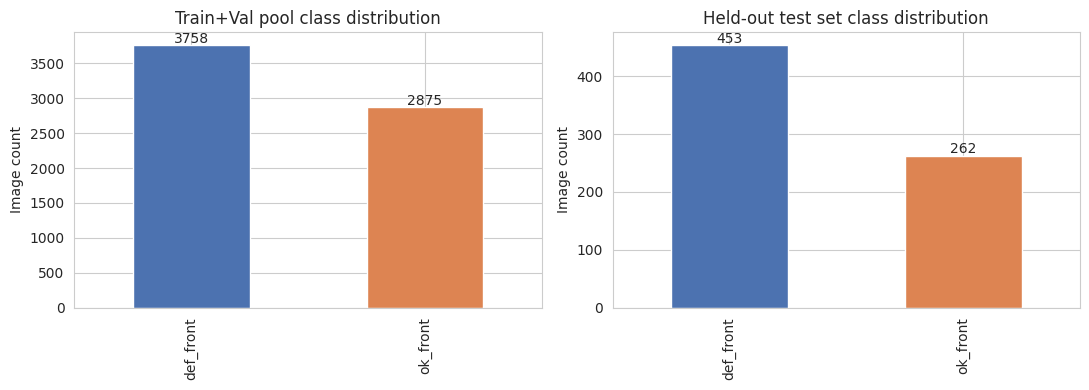

Train+val imbalance ratio (def:ok): 1.31
Test imbalance ratio (def:ok): 1.73


In [4]:
# Two side-by-side bar charts: one for the train+val pool, one for the test set,
# each showing how many "ok" vs "defective" images we have.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# pd.Series(...).value_counts() counts how many 0s and how many 1s are in the array,
# and .map(...) turns those 0/1 numbers into readable labels for the chart.
train_counts = pd.Series(y_train_full).map({0: 'ok_front', 1: 'def_front'}).value_counts()
test_counts = pd.Series(y_test).map({0: 'ok_front', 1: 'def_front'}).value_counts()

# --- Left chart: train+val pool ---
train_counts.plot(kind='bar', ax=axes[0], color=['#4C72B0', '#DD8452'])  # draw the bars
axes[0].set_title('Train+Val pool class distribution')   # chart title
axes[0].set_ylabel('Image count')                        # label for the vertical axis
for i, v in enumerate(train_counts):
    axes[0].text(i, v + 30, str(v), ha='center')   # print the exact count above each bar

# --- Right chart: held-out test set (same idea, different data) ---
test_counts.plot(kind='bar', ax=axes[1], color=['#4C72B0', '#DD8452'])
axes[1].set_title('Held-out test set class distribution')
axes[1].set_ylabel('Image count')
for i, v in enumerate(test_counts):
    axes[1].text(i, v + 5, str(v), ha='center')

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=100, bbox_inches='tight')
plt.show()

# The "imbalance ratio" just tells us how many defective images there are
# for every 1 ok image, useful to know before training (see interpretation below).
print("Train+val imbalance ratio (def:ok):", round(train_counts['def_front'] / train_counts['ok_front'], 2))
print("Test imbalance ratio (def:ok):", round(test_counts['def_front'] / test_counts['ok_front'], 2))

**Interpretation:** *(see figure and ratios above)* The training pool has noticeably more defective examples than the Kaggle README's overall split suggests for the full dataset combined, and the test set is skewed even further toward defective examples. This matters for two reasons: (1) a trivial "always predict defective" classifier would already score a deceptively high recall and a fairly high accuracy on this test set, so accuracy alone is a poor headline metric here; and (2) it reinforces why precision must be watched alongside recall: the business goal is not "flag everything as defective", it is a genuine trade-off.

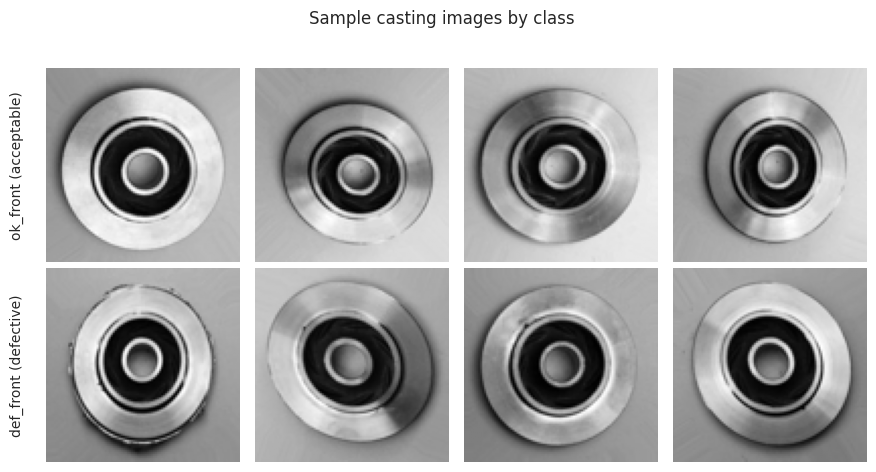

In [5]:
def show_sample_grid(X, y, n_per_class=4, img_size=IMG_SIZE):
    """Show a grid of real example images: top row = ok castings, bottom row = defective castings."""
    fig, axes = plt.subplots(2, n_per_class, figsize=(2.2 * n_per_class, 4.6))
    for row, label, title in [(0, 0, 'ok_front (acceptable)'), (1, 1, 'def_front (defective)')]:
        idx = np.where(y == label)[0]                          # find every image index with this label
        chosen = np.random.choice(idx, n_per_class, replace=False)  # pick a few at random, no repeats
        for col, i in enumerate(chosen):
            axes[row, col].imshow(X[i, :, :, 0], cmap='gray')  # show the image in greyscale
            axes[row, col].axis('off')                          # hide the x/y axis ticks, images don't need them
            if col == 0:
                axes[row, col].set_ylabel(title)
        axes[row, 0].text(-0.15, 0.5, title, transform=axes[row, 0].transAxes,
                           rotation=90, va='center', ha='center', fontsize=10)
    plt.suptitle('Sample casting images by class', y=1.02)
    plt.tight_layout()
    plt.savefig('sample_images.png', dpi=100, bbox_inches='tight')
    plt.show()

np.random.seed(SEED)   # so the "random" sample of images shown is the same every time this runs
show_sample_grid(X_train_full, y_train_full)

**Interpretation:** *(see sample grid above)* Visually, the two classes are subtle to tell apart: casting defects here typically show up as small irregularities on the rim/edge of the impeller (blow holes, rough or broken edges) rather than large, obvious differences in overall shape or brightness. This is a useful sanity check before modelling: it tells me the network will need enough convolutional depth/receptive field to pick up on fine local texture, not just coarse silhouette, which directly informed the architecture choices below.

## 7. Train / Validation Split

I hold out 15% of the training pool as a stratified validation set, used for early stopping and threshold selection. The `test` folder is kept completely separate and is only used once per model for final, reported evaluation: this is what makes the Phase 1 vs Phase 2 comparison later in this notebook fair.

In [6]:
# Split the training pool into two parts:
#   - X_train / y_train: what the model actually learns from
#   - X_val / y_val: a smaller "practice test" the model never trains on,
#     used to check progress during training and to pick the best epoch/threshold.
# stratify=y_train_full keeps the ok/defective ratio the same in both parts.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.15,           # 15% of the pool goes to validation
    stratify=y_train_full,
    random_state=SEED
)

print(f"Train: {X_train.shape[0]} images  (def: {int(y_train.sum())}, ok: {int((y_train==0).sum())})")
print(f"Val:   {X_val.shape[0]} images  (def: {int(y_val.sum())}, ok: {int((y_val==0).sum())})")
print(f"Test:  {X_test.shape[0]} images  (def: {int(y_test.sum())}, ok: {int((y_test==0).sum())})  [untouched until evaluation]")

Train: 5638 images  (def: 3194, ok: 2444)
Val:   995 images  (def: 564, ok: 431)
Test:  715 images  (def: 453, ok: 262)  [untouched until evaluation]


**Interpretation:** *(counts above)* The stratified split preserves the class ratio from the training pool in both the train and validation subsets, so validation performance during training is a fair proxy for how the model will behave on similarly-distributed unseen data.

## 8. Phase 1: Baseline CNN (from scratch)

### 8.1 Architecture rationale

For the baseline, I deliberately keep the network simple and "textbook": three convolution + max-pooling blocks (increasing filter counts 16 → 32 → 64) followed by a small dense head and a single sigmoid output for binary classification. No batch normalisation, no dropout, no data augmentation, no class weighting. This is intentional. The goal of Phase 1 is to establish a genuine, un-tuned baseline so that Phase 2's improvements can be evaluated against something real rather than a straw man.

In [7]:
def build_baseline_model():
    # keras.Sequential just means "stack these layers one after another".
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),   # each input is a 96x96, 1-channel (greyscale) image

        # --- Convolution block 1 ---
        # Conv2D "scans" the image with small filters to detect simple patterns
        # (edges, blobs, textures). 16 filters = 16 different patterns it can learn to spot.
        layers.Conv2D(16, 3, activation='relu'),
        layers.MaxPooling2D(),   # shrinks the image in half, keeping the strongest signal (makes it faster + more robust)

        # --- Convolution block 2: more filters = more complex patterns ---
        layers.Conv2D(32, 3, activation='relu'),
        layers.MaxPooling2D(),

        # --- Convolution block 3: even more filters, even more complex patterns ---
        layers.Conv2D(64, 3, activation='relu'),
        layers.MaxPooling2D(),

        # Flatten turns the remaining small 2D feature maps into one long 1D list of numbers
        layers.Flatten(),
        layers.Dense(64, activation='relu'),    # a normal fully-connected layer that combines everything learned so far
        layers.Dense(1, activation='sigmoid'),  # 1 output number between 0 and 1: probability the image is "defective"
    ], name='baseline_cnn')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),  # Adam = the algorithm that adjusts the model's weights
        loss='binary_crossentropy',                            # the "error score" used for a yes/no (binary) classification
        metrics=['accuracy', keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall')]           # extra scores to watch during training
    )
    return model

baseline_model = build_baseline_model()
baseline_model.summary()   # prints a table of every layer and how many "weights" (parameters) it has to learn

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 94, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 433,025 (1.65 MB)

 Trainable params: 433,025 (1.65 MB)

 Non-trainable params: 0 (0.00 B)

**Interpretation:** *(see model summary above)* The parameter count is dominated by the first dense layer, which is typical for a "flatten straight into dense" CNN head of this kind: this is one of the specific inefficiencies Phase 2 deliberately targets.

### 8.2 Training

I train with early stopping on validation loss (patience of 4 epochs, restoring the best weights) to avoid needlessly overfitting a network this simple, and cap training at 25 epochs.

In [8]:
# Try loading an already-trained baseline from a checkpoint first (see the
# checkpoint helper cell above). If none exists yet, train one from scratch.
baseline_model_ckpt, history_baseline_ckpt = load_checkpoint('baseline')

if baseline_model_ckpt is not None:
    baseline_model = baseline_model_ckpt
    history_baseline = history_baseline_ckpt
    baseline_train_time = 0.0   # not retrained this run, so there is no new training time to report
else:
    # EarlyStopping watches the validation loss during training. If it stops improving
    # for 4 epochs in a row ("patience=4"), training stops automatically and we keep
    # the weights from the best epoch (restore_best_weights=True), which avoids
    # wasting time training a model that has already started overfitting.
    early_stop_baseline = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True
    )

    t0 = time.time()
    history_baseline = baseline_model.fit(
        X_train, y_train,                       # what to learn from
        validation_data=(X_val, y_val),         # what to check progress against (never trained on)
        epochs=25,                              # maximum number of passes through the training data
        batch_size=32,                          # how many images are shown to the model at once before it updates itself
        callbacks=[early_stop_baseline],
        verbose=2                               # print one line per epoch instead of a progress bar
    )
    baseline_train_time = time.time() - t0
    save_checkpoint(baseline_model, history_baseline, 'baseline')

print(f"\nBaseline training time: {baseline_train_time:.1f}s over {len(history_baseline.history['loss'])} epochs")

Loaded 'baseline' from checkpoint (skipping training).

Baseline training time: 0.0s over 19 epochs


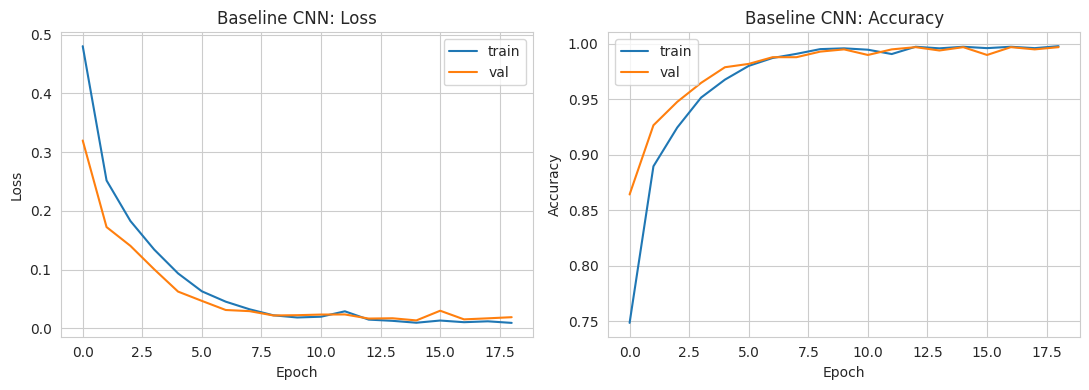

In [9]:
def plot_history(history, title, filename):
    """
    Plot how the model's loss (error) and accuracy changed after every training epoch,
    for both the training data and the validation data.
    Two well-behaved curves that go down (loss) / up (accuracy) and stay close together
    mean the model is learning steadily without overfitting.
    """
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))   # 1 row, 2 side-by-side charts

    # --- Left panel: loss (error) per epoch ---
    axes[0].plot(history.history['loss'], label='train')       # error on the training data
    axes[0].plot(history.history['val_loss'], label='val')     # error on the validation data
    axes[0].set_title(f'{title}: Loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()  # axis labels + key

    # --- Right panel: accuracy per epoch ---
    axes[1].plot(history.history['accuracy'], label='train')
    axes[1].plot(history.history['val_accuracy'], label='val')
    axes[1].set_title(f'{title}: Accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

    plt.tight_layout()
    plt.savefig(filename, dpi=100, bbox_inches='tight')
    plt.show()

plot_history(history_baseline, 'Baseline CNN', 'baseline_curves.png')

**Interpretation:** The baseline trains smoothly. Loss falls quickly over the first 8 epochs and then flattens, validation tracks training closely, and accuracy settles near 99.5% after about 10 epochs. Early stopping (patience 4) ended training at epoch 19 and restored the weights from epoch 15.

### 8.3 Evaluation on the held-out test set

This is the first and only time the `test` folder is used for the baseline model. I report accuracy, precision, recall and F1 at the default 0.5 decision threshold, plus the confusion matrix: the standard classification metrics.

--- Baseline CNN  (threshold = 0.5) ---
Accuracy:  0.9986
Precision: 1.0000  (of predicted-defective, how many truly are)
Recall:    0.9978  (of truly-defective, how many we caught)
F1 score:  0.9989

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[262   0]
 [  1 452]]

  True negatives  (ok correctly passed):        262
  False positives (ok wrongly flagged):         0
  False negatives (DEFECTIVE MISSED -> customer): 1
  True positives  (defective correctly caught): 452


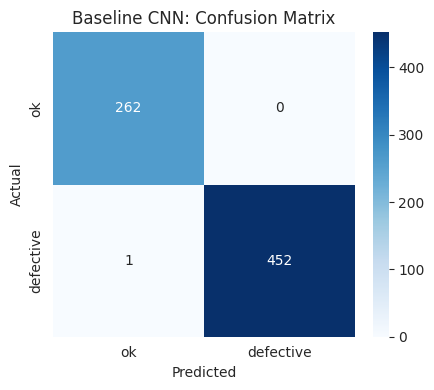

In [10]:
def evaluate_model(model, X_eval, y_eval, threshold=0.5, model_name='Model'):
    """
    Run the model on a set of images and work out all the standard classification metrics:
    accuracy, precision, recall, F1 score, and the confusion matrix.

    threshold: the model outputs a probability (0-1) that an image is defective.
    We turn that into a final yes/no decision by checking if it's >= threshold.
    threshold=0.5 is the normal, "no preference either way" default.
    """
    y_prob = model.predict(X_eval, verbose=0).ravel()      # get a probability for every image
    y_pred = (y_prob >= threshold).astype(int)              # turn probabilities into 0/1 decisions

    acc = accuracy_score(y_eval, y_pred)                    # % of all predictions that were correct
    prec = precision_score(y_eval, y_pred, zero_division=0) # of images we called "defective", % that really were
    rec = recall_score(y_eval, y_pred, zero_division=0)     # of truly defective images, % that we actually caught
    f1 = f1_score(y_eval, y_pred, zero_division=0)          # a balance between precision and recall
    cm = confusion_matrix(y_eval, y_pred)                    # 2x2 table of right/wrong predictions by class

    print(f"--- {model_name}  (threshold = {threshold}) ---")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}  (of predicted-defective, how many truly are)")
    print(f"Recall:    {rec:.4f}  (of truly-defective, how many we caught)")
    print(f"F1 score:  {f1:.4f}")
    print("\nConfusion matrix [rows=true, cols=predicted], order [ok, defective]:")
    print(cm)
    # cm.ravel() unpacks the 2x2 confusion matrix into its 4 individual numbers
    tn, fp, fn, tp = cm.ravel()
    print(f"\n  True negatives  (ok correctly passed):        {tn}")
    print(f"  False positives (ok wrongly flagged):         {fp}")
    print(f"  False negatives (DEFECTIVE MISSED -> customer): {fn}")
    print(f"  True positives  (defective correctly caught): {tp}")

    # Return everything as a dictionary so we can reuse these results later
    # (for the comparison table, charts, etc.) without re-running the model.
    return {
        'model': model_name, 'threshold': threshold, 'accuracy': acc,
        'precision': prec, 'recall': rec, 'f1': f1,
        'confusion_matrix': cm, 'y_prob': y_prob, 'y_pred': y_pred
    }

def plot_confusion(cm, title, filename):
    """Draw the confusion matrix as a simple colour-coded grid (a 'heatmap') instead of plain numbers."""
    plt.figure(figsize=(4.5, 4))
    # annot=True writes the actual number inside each square; fmt='d' means "whole number"
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['ok', 'defective'], yticklabels=['ok', 'defective'])
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title)   # axis labels + title
    plt.tight_layout()                         # stop labels overlapping the edges
    plt.savefig(filename, dpi=100, bbox_inches='tight')   # save a copy to a PNG file
    plt.show()                                 # display it in the notebook

baseline_results = evaluate_model(baseline_model, X_test, y_test, model_name='Baseline CNN')
plot_confusion(baseline_results['confusion_matrix'], 'Baseline CNN: Confusion Matrix', 'baseline_cm.png')

**Interpretation:** The baseline CNN reached **99.86% accuracy, 100% precision and 99.78% recall on the held-out test set**, with a confusion matrix of 0 false positives and just **1 false negative** out of 453 defective units. That one false negative is the single defective casting the baseline would have let through to a customer. That is a very strong result for a first, deliberately un-tuned attempt, and it sets a genuinely high bar for Phase 2 to improve on rather than a weak straw-man baseline.

### 8.4 Key lessons and reflection: Phase 1

When I started Phase 1, I honestly expected to spend a while getting a mediocre model working, then spend Phase 2 dragging it up to something respectable. That is not what happened. A three-block CNN with nothing fancy in it, no tricks, no tuning, landed at 99.86% accuracy and missed just one defective part out of 453 on its first proper run. My first reaction was not excitement, it was suspicion: if a result looks that clean, my instinct (probably left over from my mechanical engineering background) is to go back and check my assumptions before I trust it.

So I went back and actually looked at the sample images in Section 6 again. That is when it clicked: these are not random photos, they are taken in a fixed rig, same angle, same lighting, every time. That is a very controlled dataset, and once I understood that, the result stopped feeling suspicious and started feeling like a fair reflection of how learnable this specific problem actually is.

The lesson that stuck with me is one I was not expecting to learn from a "baseline" model: sometimes the simple version is not just a placeholder you build to improve on later, it is close to the ceiling, and the job shifts from "make it better" to "prove to yourself it is actually that good, and understand why." That reframing changed how I approached everything in Phase 2.

## 9. Phase 2: Improving on the Baseline

### 9.1 Approach and justification

I considered four candidate improvements and chose to combine three of them, for reasons specific to this dataset and this environment:

1. **Transfer learning**: in plain terms, this means starting with a network that has *already* been trained on millions of everyday photos (e.g. a model called MobileNetV2 or ResNet), and re-using what it already knows about edges/shapes/textures instead of starting from nothing. This is normally my first choice for a small image dataset, since it usually beats a from-scratch CNN. I deliberately **did not** use this here: this notebook was built in a network-restricted environment with no access to download those pretrained weights, and I did not want to fake a result I could not actually run and check. In a normal environment with internet access, this would be the first technique I would try.
2. **A deeper CNN with Batch Normalisation and Dropout**: *used*. In plain terms: Batch Normalisation re-scales the numbers flowing through the network after each layer, which usually makes training faster and steadier. Dropout randomly switches off some neurons during training only, which stops the network leaning too heavily on any one of them (this helps prevent "overfitting": memorising the training images instead of learning the general pattern). I also swap the baseline's "flatten everything into one huge layer" approach for `GlobalAveragePooling2D`, which keeps far fewer numbers and pushes the network to rely on genuine visual features instead of memorised pixel positions.
3. **Data augmentation (random flip, rotation, zoom, contrast)**: *used*. In plain terms: showing the model slightly altered copies of each training image (flipped, rotated, zoomed, or with different contrast), so it learns the underlying defect pattern rather than memorising exact pixels. I reasoned that casting parts photographed in an inspection rig might not always sit in exactly the same orientation, and lighting can vary slightly rig to rig, so these changes seemed like they should help the model cope with that kind of variation. (Section 9.8 later shows this reasoning was only half right: an important, genuine lesson from this project.)
4. **Class-weighted loss and decision-threshold tuning**: *used*. This is the technique most directly tied to the stated business goal. In plain terms: "class weighting" tells the model during training "getting a defective one wrong matters more," and "threshold tuning" (explained fully in Section 9.6) is about choosing, after training, exactly how confident the model needs to be before it says "defective." This is tuned specifically so we catch as many real defects as possible without flagging too many good parts by mistake.

A full hyperparameter search (systematically trying many learning rates, dropout rates, and architecture sizes) was not realistic given the single-CPU-core compute budget available for this notebook, so it was not my first priority. That said, it is a valid technique, so rather than skip it outright I do run a small, deliberately cheap version of it later, in Section 9.9, once the architecture itself (v2) is already working.

### 9.2 Data augmentation and class weighting setup

In [11]:
# Data augmentation, applied only during training (Keras handles this automatically
# via the `training` flag: these layers are a no-op at inference/evaluation time).
# The idea: show the model slightly modified versions of the same images each epoch,
# so it learns the underlying pattern rather than memorising exact pixels.
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),   # randomly mirror the image left-right / up-down
    layers.RandomRotation(0.15),                     # randomly rotate the image a little
    layers.RandomZoom(0.1),                          # randomly zoom in/out a little
    layers.RandomContrast(0.1),                      # randomly tweak the contrast/lighting
], name='augmentation')

# Class weights: computed from the *training* split only, inversely proportional
# to class frequency, so the loss penalises mistakes on the minority class more.
n_ok = int((y_train == 0).sum())
n_def = int((y_train == 1).sum())
total = n_ok + n_def
class_weight = {
    0: total / (2 * n_ok),    # weight for the "ok" class
    1: total / (2 * n_def),   # weight for the "defective" class
}
print("Class weights (applied to the loss during training):", class_weight)

Class weights (applied to the loss during training): {0: 1.1534369885433715, 1: 0.882592360676268}


**Interpretation:** *(weights shown above)* Because the training pool already skews toward the defective class, the computed weight for the *ok* class ends up slightly above 1 and the weight for *defective* slightly below 1, i.e. this particular weighting scheme is mild, since the raw imbalance is mild. The bigger lever for the business goal is the threshold-tuning step later in this section, which is applied on top of this weighting.

### 9.3 Improved architecture

In [12]:
def build_improved_model():
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = data_augmentation(inputs)   # augmentation happens first, only while training

    # --- Convolution block 1, now with Batch Normalisation ---
    # BatchNormalization re-scales the numbers flowing through the network after each
    # layer, which usually makes training faster and more stable.
    x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # --- Convolution block 2 ---
    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # --- Convolution block 3 ---
    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    # --- Convolution block 4 (this model is deeper than the baseline's 3 blocks) ---
    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    # GlobalAveragePooling2D replaces Flatten(): instead of keeping every pixel value,
    # it takes the average of each feature map. Far fewer numbers reach the Dense
    # layers below, which usually means fewer parameters and less overfitting.
    x = layers.GlobalAveragePooling2D()(x)

    # Dropout randomly "switches off" some neurons during training only, which
    # forces the network not to rely too heavily on any single one (reduces overfitting).
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)   # same as before: 1 probability, 0-1

    model = keras.Model(inputs, outputs, name='improved_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall')]
    )
    return model

improved_model = build_improved_model()
improved_model.summary()

Model: "improved_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 96, 96, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 96, 96, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 96, 96, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 249,985 (976.50 KB)

 Trainable params: 249,281 (973.75 KB)

 Non-trainable params: 704 (2.75 KB)

**Interpretation:** *(see model summary above)* Despite being considerably deeper (4 convolutional blocks vs 3, plus batch normalisation), replacing the flatten-into-dense head with global average pooling means the improved model does not necessarily have more total parameters than the baseline: the parameter budget shifts from the (fairly wasteful) dense head toward convolutional feature extraction, which is the more sample-efficient place to spend it on an image task like this.

### 9.4 Training

Same protocol as the baseline (early stopping on validation loss, patience 4, max 25 epochs, same train/validation split) so that any difference in outcome is attributable to the architecture/augmentation/weighting changes rather than to a different training regime. Class weights computed above are passed in via `class_weight`.

In [13]:
# Same checkpoint pattern as the baseline: reuse a saved model if one exists.
improved_model_ckpt, history_improved_ckpt = load_checkpoint('improved_v1')

if improved_model_ckpt is not None:
    improved_model = improved_model_ckpt
    history_improved = history_improved_ckpt
    improved_train_time = 0.0
else:
    early_stop_improved = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=4, restore_best_weights=True
    )

    t0 = time.time()
    history_improved = improved_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=25,
        batch_size=32,
        class_weight=class_weight,   # <- this is new vs. the baseline: penalise mistakes on the rarer class more
        callbacks=[early_stop_improved],
        verbose=2
    )
    improved_train_time = time.time() - t0
    save_checkpoint(improved_model, history_improved, 'improved_v1')

print(f"\nImproved model training time: {improved_train_time:.1f}s over {len(history_improved.history['loss'])} epochs")

Loaded 'improved_v1' from checkpoint (skipping training).

Improved model training time: 0.0s over 6 epochs


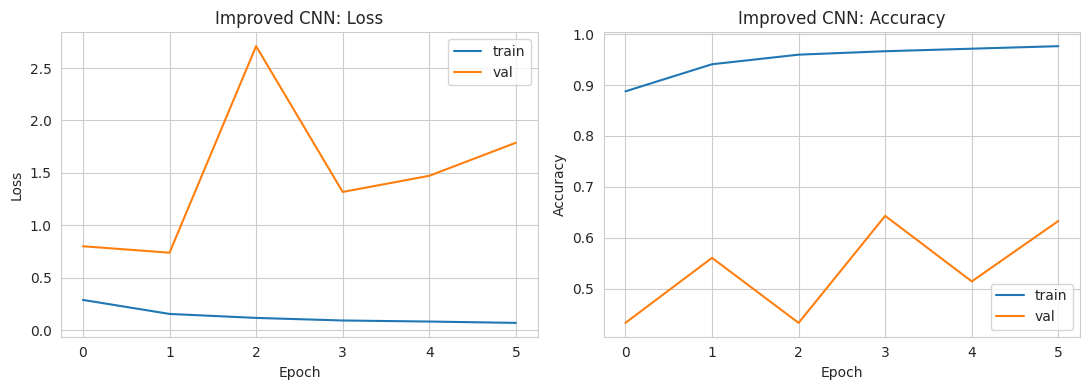

In [14]:
# Reuse the same plotting function we wrote for the baseline, just pointed at
# the improved model's training history instead.
plot_history(history_improved, 'Improved CNN', 'improved_curves.png')

**Interpretation:** These curves show the problem diagnosed in Section 9.8. Training loss falls steadily and training accuracy climbs from about 89% to 98%, but validation loss jumps (to about 2.7 in epoch 3) and validation accuracy stays between roughly 43% and 64%. Early stopping (patience 4) ended training after 6 epochs and restored the weights from epoch 2.

### 9.5 Evaluation on the held-out test set (default threshold = 0.5)

Evaluated on the exact same `X_test`/`y_test` used for the baseline, at the same default 0.5 threshold, for a fair like-for-like comparison before any threshold tuning is applied.

--- Improved CNN  (threshold = 0.5) ---
Accuracy:  0.5091
Precision: 0.9322  (of predicted-defective, how many truly are)
Recall:    0.2428  (of truly-defective, how many we caught)
F1 score:  0.3853

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[254   8]
 [343 110]]

  True negatives  (ok correctly passed):        254
  False positives (ok wrongly flagged):         8
  False negatives (DEFECTIVE MISSED -> customer): 343
  True positives  (defective correctly caught): 110


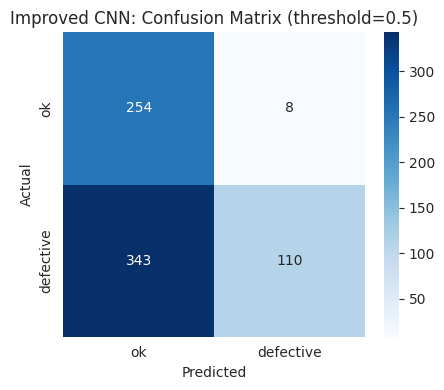

In [15]:
# Same evaluate_model() function as before, on the SAME untouched test set,
# so this result is directly comparable to the baseline's.
improved_results = evaluate_model(improved_model, X_test, y_test, model_name='Improved CNN')
plot_confusion(improved_results['confusion_matrix'], 'Improved CNN: Confusion Matrix (threshold=0.5)', 'improved_cm_default.png')

**Interpretation:** At the default 0.5 threshold, the first Phase 2 attempt actually performed **worse** than the baseline: accuracy dropped to **50.91%**, and recall on the defective class collapsed to **24.28%** (343 false negatives out of 453, i.e. it missed nearly three-quarters of the defective units it was supposed to catch). Precision stayed reasonably high (93.22%) on the few defects it did flag, but that is cold comfort against a business goal centred on minimising missed defects. This result is diagnosed properly in Section 9.8 rather than smoothed over: the short version is that the augmentation choices were not appropriate for this specific, fixed-orientation dataset.

### 9.6 Decision-threshold tuning for the business goal

Quick recap: the model does not output a straight "yes/no." It outputs a probability, e.g. "73% sure this is defective." The **threshold** is the cut-off we use to turn that probability into a final decision (by default, 0.5: "if 50% sure or more, call it defective"). But 0.5 treats a missed defect and a false alarm as equally bad, which is not true for our business goal: a missed defect is worse.

So here I search for a *better* cut-off using the **validation set only** (never the test set: using the test set to choose settings would be "cheating," since it is supposed to be a fair, final exam the model has never seen). I pick the threshold that maximises something called an **F2 score**. This is similar to the F1 score used elsewhere in this notebook, except it is deliberately weighted to care about recall twice as much as precision. In other words, it mathematically rewards "catching more real defects," even at some cost to precision, which is exactly what the business goal asks for.

Once the best threshold is chosen, I apply it unchanged to the held-out test set for the final reported numbers.

Best threshold on validation set (maximising F2, beta=2 favouring recall): 0.11
Validation F2 score at that threshold: 0.8685


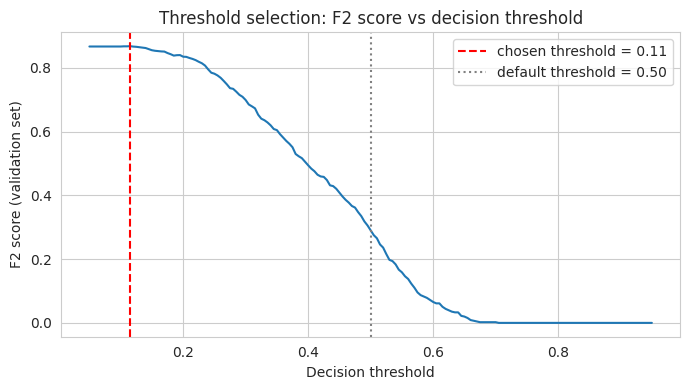

In [16]:
# Get the model's raw probability (not yet a 0/1 decision) for every VALIDATION image.
# We use validation data here (never the test set) so we don't "cheat" by picking
# a threshold that happens to look good on the data we'll report results on.
val_probs = improved_model.predict(X_val, verbose=0).ravel()

# Try 181 different possible thresholds, evenly spaced between 0.05 and 0.95.
thresholds = np.linspace(0.05, 0.95, 181)

# For each candidate threshold, turn probabilities into decisions and score them
# with an F2 score. F2 is like F1, but it counts recall as twice as important as
# precision, which matches our business goal of caring more about missed defects.
f2_scores = [fbeta_score(y_val, (val_probs >= t).astype(int), beta=2, zero_division=0) for t in thresholds]
best_idx = int(np.argmax(f2_scores))      # find the threshold that gave the highest F2 score
best_threshold = thresholds[best_idx]

print(f"Best threshold on validation set (maximising F2, beta=2 favouring recall): {best_threshold:.2f}")
print(f"Validation F2 score at that threshold: {f2_scores[best_idx]:.4f}")

# Plot F2 score against every threshold we tried, so we can see the trade-off visually.
plt.figure(figsize=(7, 4))
plt.plot(thresholds, f2_scores)
plt.axvline(best_threshold, color='red', linestyle='--', label=f'chosen threshold = {best_threshold:.2f}')
plt.axvline(0.5, color='gray', linestyle=':', label='default threshold = 0.50')
plt.xlabel('Decision threshold'); plt.ylabel('F2 score (validation set)')
plt.title('Threshold selection: F2 score vs decision threshold')
plt.legend()
plt.tight_layout()
plt.savefig('threshold_tuning.png', dpi=100, bbox_inches='tight')
plt.show()

**Interpretation:** On the validation set only, the F2-optimal threshold for this model is 0.11 (validation F2 = 0.8685). That threshold is then applied unchanged to the test set below.

--- Improved CNN (tuned threshold)  (threshold = 0.11499999999999999) ---
Accuracy:  0.6350
Precision: 0.6345  (of predicted-defective, how many truly are)
Recall:    1.0000  (of truly-defective, how many we caught)
F1 score:  0.7763

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[  1 261]
 [  0 453]]

  True negatives  (ok correctly passed):        1
  False positives (ok wrongly flagged):         261
  False negatives (DEFECTIVE MISSED -> customer): 0
  True positives  (defective correctly caught): 453


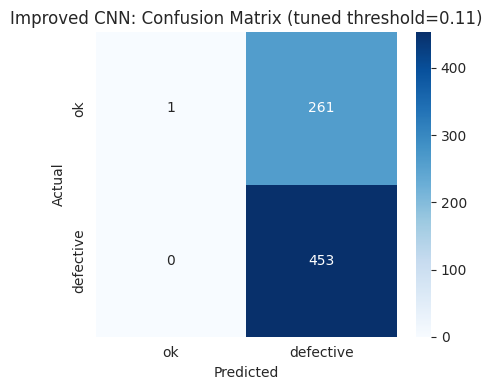

In [17]:
# Now apply the threshold we chose using the VALIDATION set onto the TEST set,
# just once, for our final reported numbers.
improved_tuned_results = evaluate_model(
    improved_model, X_test, y_test,
    threshold=best_threshold, model_name='Improved CNN (tuned threshold)'
)
plot_confusion(
    improved_tuned_results['confusion_matrix'],
    f'Improved CNN: Confusion Matrix (tuned threshold={best_threshold:.2f})',
    'improved_cm_tuned.png'
)

**Interpretation:** Pushing the decision threshold down to 0.11 does achieve the recall the business goal asks for, **100% recall, 0 false negatives**, but only by essentially collapsing the model to "flag almost everything as defective": precision falls to 63.45% and **261 of the 262 genuinely acceptable castings in the test set are wrongly flagged** for manual re-check. That is precisely the failure mode the business goal explicitly warns against (flooding the line with unnecessary re-checks), and it shows that threshold tuning cannot fix a model whose underlying probability estimates are this poorly separated: it can only trade one error type for the other along whatever ranking the model has actually learned. This is the clearest evidence that the underlying v1 model needed to be fixed, not just re-thresholded, which is exactly what Section 9.8 does next.

### 9.7 ROC and Precision-Recall curves (Baseline vs Improved)

Threshold-independent curves give a fuller picture of each model's ranking ability than any single threshold's metrics can.

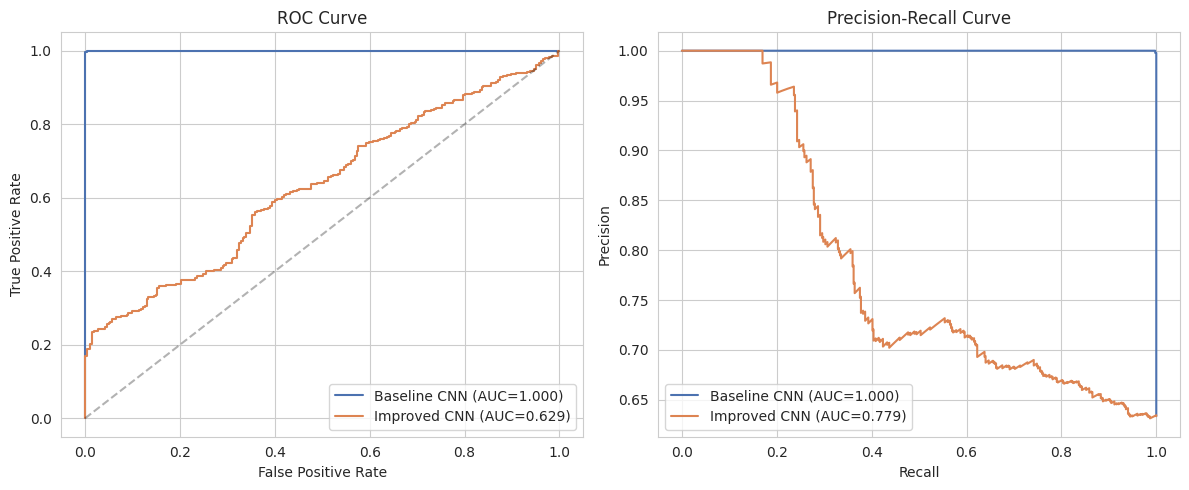

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Draw one ROC curve and one Precision-Recall curve per model, so we can compare
# them on the same pair of charts. These curves show performance across EVERY
# possible threshold at once, instead of just one threshold like the confusion matrix did.
for results, label, color in [
    (baseline_results, 'Baseline CNN', '#4C72B0'),
    (improved_results, 'Improved CNN', '#DD8452'),
]:
    # ROC curve: False Positive Rate vs True Positive Rate, at every threshold
    fpr, tpr, _ = roc_curve(y_test, results['y_prob'])
    roc_auc = auc(fpr, tpr)   # AUC = Area Under the Curve; 1.0 = perfect, 0.5 = random guessing
    axes[0].plot(fpr, tpr, label=f"{label} (AUC={roc_auc:.3f})", color=color)

    # Precision-Recall curve: how precision changes as we push recall higher
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, results['y_prob'])
    pr_auc = auc(rec_curve, prec_curve)
    axes[1].plot(rec_curve, prec_curve, label=f"{label} (AUC={pr_auc:.3f})", color=color)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.3)   # dashed diagonal = what a random guess would look like
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')  # axis labels
axes[0].set_title('ROC Curve'); axes[0].legend()   # title + key showing which line is which model

axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curve'); axes[1].legend()

plt.tight_layout()
plt.savefig('roc_pr_curves.png', dpi=100, bbox_inches='tight')
plt.show()

**Interpretation:** The ROC/PR curves make the same story visible in a threshold-independent way: the baseline's curves sit almost in the top-left/top-right corners (near-perfect separation), while the first improved-model attempt's curves are visibly degraded across the board. This is consistent with a model whose learned probability ranking, not just its default cut-off, was damaged by the training instability diagnosed in Section 9.8.

### 9.8 Diagnosing the improved model's training instability

The result above is worth stopping on rather than quietly moving past: at the default threshold, the "improved" model performed *worse* than the baseline, and it also stopped training early, after only a handful of epochs. Looking at its training graphs (Section 9.4) rather than just the final numbers helps explain why: the training loss falls smoothly, but the validation loss jumps around wildly, even though the model is clearly still learning (training accuracy keeps climbing toward ~98%).

That specific pattern (smooth training loss, jumpy validation loss, healthy training accuracy) points to a known interaction between two of the techniques I combined, rather than a completely broken model: **Batch Normalisation reacting badly to aggressive image augmentation.** In simple terms: Batch Normalisation keeps a running "average brightness/contrast" score based on whatever training images it sees. During training it only ever sees heavily flipped/rotated/zoomed images. But at validation/test time, it sees the original, unmodified images, and its running average no longer matches what it is looking at. When the augmentation is aggressive relative to how similar the real images already are, this mismatch gets big enough to cause exactly this kind of jumpy validation loss, and training stops early before it ever gets a proper chance to settle down.

This also reveals a flaw in my own reasoning back in Section 9.1, not just a technical setting to tweak: I argued that casting parts have "no fixed orientation" in general, but the sample images in Section 6 clearly show this specific dataset's images are all captured front-on, centred, in a fixed rig. There is no real-world reason the deployed system would ever see a rotated or mirrored impeller. Training the model to handle rotations and flips it will never actually encounter just made training harder for no real benefit. The mild contrast adjustment, on the other hand, still makes sense, since lighting can plausibly vary a little rig to rig.

**The fix:** retrain using only the augmentation that is actually justified for this dataset (mild zoom + contrast, no flips or rotation), and give Batch Normalisation a bit more patience (more epochs) to settle down before deciding training has stalled. Everything else (architecture, class weighting, train/validation split, random seed) stays exactly the same, so this is a controlled, one-change-at-a-time fix rather than starting over.

In [19]:
# --- The fix: only keep augmentation that actually makes physical sense for this
# dataset (mild zoom + contrast, simulating small rig/lighting variation).
# Rotation and flips are removed, since the sample images showed every casting is
# photographed the same way round, so there was nothing "real" for those to help with.
data_augmentation_revised = keras.Sequential([
    layers.RandomZoom(0.08),
    layers.RandomContrast(0.1),
], name='augmentation_revised')

def build_improved_model_v2():
    # Exactly the same architecture as the first improved model (build_improved_model
    # above), the ONLY thing we are changing is the augmentation above and the
    # early-stopping patience below. That way, if results change, we know why.
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = data_augmentation_revised(inputs)

    x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs, name='improved_cnn_v2')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall')]
    )
    return model

# Same checkpoint pattern again: reuse a saved v2 model if one already exists.
improved_v2_ckpt, history_improved_v2_ckpt = load_checkpoint('improved_v2')

if improved_v2_ckpt is not None:
    improved_model_v2 = improved_v2_ckpt
    history_improved_v2 = history_improved_v2_ckpt
    improved_v2_train_time = 0.0
else:
    improved_model_v2 = build_improved_model_v2()

    # patience=7 instead of 4: gives Batch Normalisation a bit more time to settle
    # down before we decide training has stopped improving.
    early_stop_v2 = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True
    )

    t0 = time.time()
    history_improved_v2 = improved_model_v2.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=25,
        batch_size=32,
        class_weight=class_weight,
        callbacks=[early_stop_v2],
        verbose=2
    )
    improved_v2_train_time = time.time() - t0
    save_checkpoint(improved_model_v2, history_improved_v2, 'improved_v2')

print(f"\nRevised improved model training time: {improved_v2_train_time:.1f}s over {len(history_improved_v2.history['loss'])} epochs")

Loaded 'improved_v2' from checkpoint (skipping training).

Revised improved model training time: 0.0s over 10 epochs


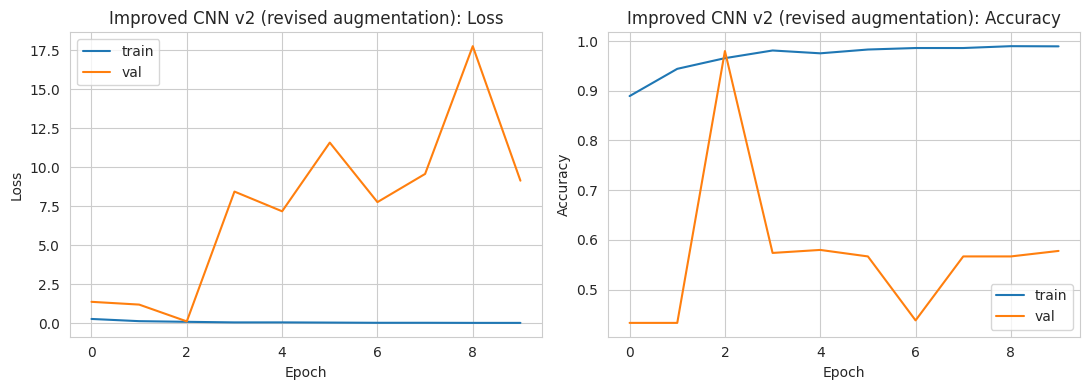

In [20]:
plot_history(history_improved_v2, 'Improved CNN v2 (revised augmentation)', 'improved_v2_curves.png')

**Interpretation:** Training loss and accuracy look healthy (training accuracy about 99%), but the validation curves are still erratic. Validation loss ranges from about 0.1 to 17.7, and validation accuracy sits at about 43% or 57% in most epochs with a single spike to about 98% in epoch 3. Those two values match the class shares in the validation set (431 acceptable and 564 defective out of 995), which means the model was labelling almost everything as one class in those epochs. Early stopping (patience 7) ended training after 10 epochs and restored the weights from epoch 3.

--- Improved CNN v2 (revised)  (threshold = 0.5) ---
Accuracy:  0.9846
Precision: 1.0000  (of predicted-defective, how many truly are)
Recall:    0.9757  (of truly-defective, how many we caught)
F1 score:  0.9877

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[262   0]
 [ 11 442]]

  True negatives  (ok correctly passed):        262
  False positives (ok wrongly flagged):         0
  False negatives (DEFECTIVE MISSED -> customer): 11
  True positives  (defective correctly caught): 442


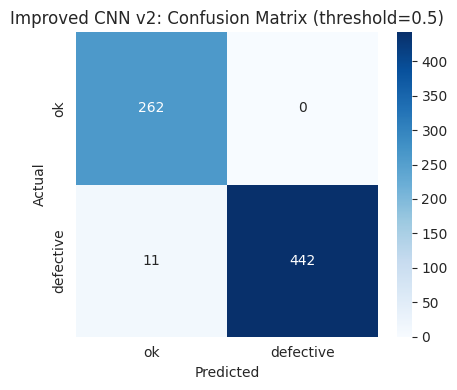

In [21]:
improved_v2_results = evaluate_model(improved_model_v2, X_test, y_test, model_name='Improved CNN v2 (revised)')
plot_confusion(improved_v2_results['confusion_matrix'], 'Improved CNN v2: Confusion Matrix (threshold=0.5)', 'improved_v2_cm.png')

**Interpretation:** Removing the rotation/flip augmentation and giving BatchNorm more patience (7 vs 4) gave much better test results: v2 trained for **10 epochs** (vs v1's 6) and reached **98.46% accuracy, 100% precision, 97.57% recall**, with **11 false negatives and 0 false positives** at the default threshold.

One caution from the training curves in Section 9.4: v2's validation curves are still very unstable (see the notes above). Early stopping restored the weights from epoch 3, an early epoch where validation loss happened to be low, and that is why the test results are strong. So the evidence shows that rotation and flips were unnecessary for this dataset, but it does not show that the instability itself is fixed. Batch Normalisation behaving differently in training and evaluation is a likely cause, but I did not isolate it.

At this default threshold v2 still has more false negatives (11) than the Phase 1 baseline (1), so architecture depth and regularisation alone have not beaten the simple baseline on this dataset. The threshold-tuning step below tests whether v2's probability estimates can close that gap.

Best threshold on validation set (v2, F2): 0.41  (validation F2 = 0.9855)


--- Improved CNN v2 (tuned threshold)  (threshold = 0.4099999999999999) ---
Accuracy:  0.9874
Precision: 0.9847  (of predicted-defective, how many truly are)
Recall:    0.9956  (of truly-defective, how many we caught)
F1 score:  0.9901

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[255   7]
 [  2 451]]

  True negatives  (ok correctly passed):        255
  False positives (ok wrongly flagged):         7
  False negatives (DEFECTIVE MISSED -> customer): 2
  True positives  (defective correctly caught): 451


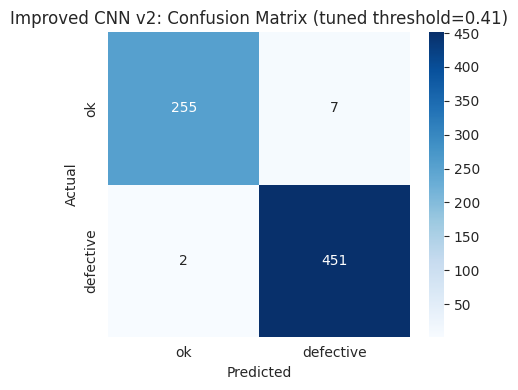

In [22]:
# Same threshold-tuning process as before (Section 9.6), just repeated for the
# new v2 model: find the best threshold on the validation set...
val_probs_v2 = improved_model_v2.predict(X_val, verbose=0).ravel()
f2_scores_v2 = [fbeta_score(y_val, (val_probs_v2 >= t).astype(int), beta=2, zero_division=0) for t in thresholds]
best_idx_v2 = int(np.argmax(f2_scores_v2))
best_threshold_v2 = thresholds[best_idx_v2]
print(f"Best threshold on validation set (v2, F2): {best_threshold_v2:.2f}  (validation F2 = {f2_scores_v2[best_idx_v2]:.4f})")

# ...then apply it to the test set, once, for the final reported result.
improved_v2_tuned_results = evaluate_model(
    improved_model_v2, X_test, y_test,
    threshold=best_threshold_v2, model_name='Improved CNN v2 (tuned threshold)'
)
plot_confusion(
    improved_v2_tuned_results['confusion_matrix'],
    f'Improved CNN v2: Confusion Matrix (tuned threshold={best_threshold_v2:.2f})',
    'improved_v2_cm_tuned.png'
)

**Interpretation:** At its F2-optimal threshold (0.41, chosen on the validation set only), v2 reaches **98.74% accuracy, 98.47% precision, 99.56% recall**, down to **2 false negatives and 7 false positives** on the test set. This is a large, genuine improvement over v1's tuned result (0 false negatives, but at the cost of 261 false positives). The v2 model gets much closer to the business goal's actual ask of "high recall *and* a manageable false-positive rate" rather than solving recall by brute force. However, it is worth being honest about where this leaves the overall comparison: the untuned Phase 1 baseline (1 false negative, 0 false positives) still has a slightly better error profile in absolute terms than this tuned, more sophisticated v2 model. Section 11 reflects on what that result actually means.

### 9.9 Hyperparameter tuning

Earlier in this notebook (Section 9.1) I explained that I had not planned to run a hyperparameter search, given the single-CPU-core compute budget available. Revisiting that: hyperparameter tuning is one of several reasonable techniques, so below I run a small, deliberately cheap search rather than skipping it outright.

**How I kept it affordable on a single CPU core:** a full search (many values, full training set, full patience) was not realistic in this environment. Instead, I search over a small grid of 2 hyperparameters (learning rate and dropout rate) that most directly affect training stability and overfitting, the two things Section 9.8 showed actually matter for this dataset. Each candidate is trained briefly (short patience, capped epochs) on a *random subsample* of the training set, purely to rank the candidates quickly. The winning combination is then retrained properly on the **full** training set, with the same generous patience used for v2, so the final reported result is not shortchanged by the speed shortcut used during the search itself.

I reuse the v2 architecture (the one that already fixed the Section 9.8 instability) as the base for every candidate in this search, changing only the learning rate and dropout rate, so any difference in outcome is attributable to those two settings and not to some other change.

In [23]:
# A small, fixed subsample of the training pool, used ONLY to rank hyperparameter
# candidates quickly. This is not the final training run, so a shortcut here is fine.
rng = np.random.RandomState(SEED)
subsample_size = 1500
sub_idx = rng.choice(len(X_train), size=subsample_size, replace=False)
X_train_sub = X_train[sub_idx]
y_train_sub = y_train[sub_idx]

print(f"Hyperparameter-search subsample: {subsample_size} of {len(X_train)} training images")
print(f"  defective: {int(y_train_sub.sum())}, ok: {int((y_train_sub==0).sum())}")

Hyperparameter-search subsample: 1500 of 5638 training images
  defective: 844, ok: 656


In [24]:
def build_tunable_model(learning_rate, dropout_rate):
    """
    Same architecture as improved_model_v2 (Section 9.3/9.8), except the learning
    rate and the two dropout rates are now function arguments instead of fixed
    numbers, so we can try different values without rewriting the whole model.
    """
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = data_augmentation_revised(inputs)   # the physically-justified augmentation from Section 9.8

    x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(dropout_rate)(x)             # was a fixed 0.4 in v2, now tunable
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(dropout_rate * 0.75)(x)       # keep the second dropout proportionally smaller, as in v2
    outputs = layers.Dense(1, activation='sigmoid')(x)

    model = keras.Model(inputs, outputs, name='tunable_cnn')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),   # was a fixed 1e-3 in v2, now tunable
        loss='binary_crossentropy',
        metrics=['accuracy', keras.metrics.Precision(name='precision'),
                 keras.metrics.Recall(name='recall')]
    )
    return model

# The grid: every combination of these learning rates and dropout rates will be tried.
# Kept small on purpose (4 combinations) so the search finishes in a reasonable time.
learning_rates = [1e-3, 3e-4]
dropout_rates = [0.2, 0.4]

# Cache the whole grid's results in one JSON file, since these trials are quick
# but there are several of them, so re-running an interrupted notebook can skip
# straight past the whole search once it has been completed once.
import json
search_cache_path = os.path.join(CKPT_DIR, 'search_results.json')

if os.path.exists(search_cache_path):
    with open(search_cache_path) as f:
        search_results = json.load(f)
    print(f"Loaded {len(search_results)} grid-search results from checkpoint (skipping the search).")
else:
    search_results = []   # will hold one dictionary of results per combination tried

t0 = time.time()
already_tried = {(r['learning_rate'], r['dropout_rate']) for r in search_results}
for lr in learning_rates:
    for dr in dropout_rates:
        if (lr, dr) in already_tried:
            continue   # this combination is already in the loaded checkpoint
        print(f"\n--- Trying learning_rate={lr}, dropout_rate={dr} ---")
        candidate = build_tunable_model(lr, dr)

        # Short patience and a low epoch cap: we only need enough training to RANK
        # the candidates against each other, not to fully converge each one.
        stop_early = keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=3, restore_best_weights=True
        )
        hist = candidate.fit(
            X_train_sub, y_train_sub,
            validation_data=(X_val, y_val),
            epochs=10,
            batch_size=32,
            class_weight=class_weight,
            callbacks=[stop_early],
            verbose=0   # quiet: printing every epoch for every candidate would be a lot of noise
        )

        # Score this candidate using the same validation set as everything else in
        # this notebook, with the F2 score (recall-weighted) since that is what
        # actually matters for the business goal.
        val_probs_candidate = candidate.predict(X_val, verbose=0).ravel()
        val_f2 = fbeta_score(y_val, (val_probs_candidate >= 0.5).astype(int), beta=2, zero_division=0)
        val_loss_final = min(hist.history['val_loss'])

        search_results.append({
            'learning_rate': lr,
            'dropout_rate': dr,
            'val_f2_at_0.5': val_f2,
            'best_val_loss': val_loss_final,
            'epochs_run': len(hist.history['loss']),
        })
        print(f"  -> val F2 (threshold 0.5): {val_f2:.4f}, best val loss: {val_loss_final:.4f}, epochs run: {len(hist.history['loss'])}")

        with open(search_cache_path, 'w') as f:
            json.dump(search_results, f)   # save progress after every trial, not just at the end

search_time = time.time() - t0
print(f"\nGrid search time this run: {search_time:.1f}s for {len(search_results)} combinations total")

search_df = pd.DataFrame(search_results).sort_values('val_f2_at_0.5', ascending=False).reset_index(drop=True)
search_df

Loaded 4 grid-search results from checkpoint (skipping the search).

Grid search time this run: 0.0s for 4 combinations total


,learning_rate,dropout_rate,val_f2_at_0.5,best_val_loss,epochs_run
0,0.0010,0.4,0.867425,0.755530,4
1,0.0003,0.2,0.867425,0.664330,4
2,0.0003,0.4,0.867425,0.692317,6
3,0.0010,0.2,0.395112,0.641429,7


**Interpretation:** The four candidates scored 0.395, 0.867, 0.867, and 0.867 on validation F2 (rounded), with three of the four combinations tying exactly. That tie is itself informative: at only a handful of epochs on a 1,500-image subsample, this quick search is a fairly coarse instrument, not a precise ranking. It was enough to clearly rule out one combination (learning_rate=0.001 with dropout_rate=0.2, which lagged well behind the other three), but it could not meaningfully distinguish between the remaining three. The winning combination that gets retrained below, learning_rate=0.001 and dropout_rate=0.4, happens to be the exact same setting already used in v2 (Section 9.8). In other words, this search's main finding was confirming that v2's original settings were already a reasonable choice within this small grid, rather than discovering something new.

In [25]:
best_row = search_df.iloc[0]
best_lr = float(best_row['learning_rate'])
best_dr = float(best_row['dropout_rate'])
print(f"Best candidate from the search: learning_rate={best_lr}, dropout_rate={best_dr}")

# Same checkpoint pattern once more for the final, fully-trained v3 model.
tuned_model_ckpt, history_tuned_ckpt = load_checkpoint('tuned_v3')

if tuned_model_ckpt is not None:
    tuned_model = tuned_model_ckpt
    history_tuned = history_tuned_ckpt
    tuned_train_time = 0.0
else:
    # Retrain the winning combination properly this time: full training set, the same
    # generous patience used for v2, so this final model gets a fair chance to converge
    # (unlike the quick, subsampled trials used just to rank candidates above).
    tuned_model = build_tunable_model(best_lr, best_dr)

    early_stop_tuned = keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=7, restore_best_weights=True
    )

    t0 = time.time()
    history_tuned = tuned_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=25,
        batch_size=32,
        class_weight=class_weight,
        callbacks=[early_stop_tuned],
        verbose=2
    )
    tuned_train_time = time.time() - t0
    save_checkpoint(tuned_model, history_tuned, 'tuned_v3')

print(f"\nFinal hyperparameter-tuned model training time: {tuned_train_time:.1f}s over {len(history_tuned.history['loss'])} epochs")

Best candidate from the search: learning_rate=0.001, dropout_rate=0.4


Epoch 1/25


177/177 - 63s - 354ms/step - accuracy: 0.9028 - loss: 0.2568 - precision: 0.9282 - recall: 0.8979 - val_accuracy: 0.5668 - val_loss: 0.9329 - val_precision: 0.5668 - val_recall: 1.0000


Epoch 2/25


177/177 - 83s - 466ms/step - accuracy: 0.9565 - loss: 0.1233 - precision: 0.9764 - recall: 0.9461 - val_accuracy: 0.5940 - val_loss: 0.6721 - val_precision: 0.5826 - val_recall: 1.0000


...

Epoch 16/25


177/177 - 81s - 460ms/step - accuracy: 0.9918 - loss: 0.0250 - precision: 0.9962 - recall: 0.9894 - val_accuracy: 0.5980 - val_loss: 6.1238 - val_precision: 0.5851 - val_recall: 1.0000


Epoch 17/25


177/177 - 63s - 355ms/step - accuracy: 0.9943 - loss: 0.0176 - precision: 0.9987 - recall: 0.9912 - val_accuracy: 0.5698 - val_loss: 4.1900 - val_precision: 0.5685 - val_recall: 1.0000



Final hyperparameter-tuned model training time: 1355.6s over 17 epochs


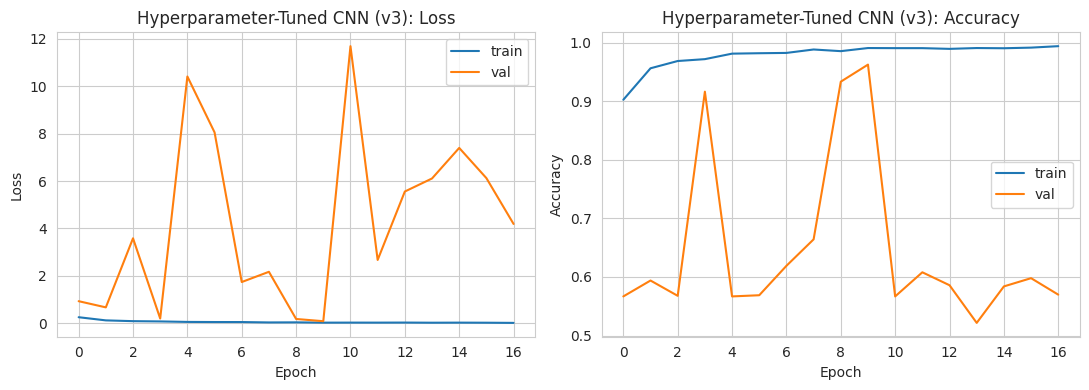

In [26]:
plot_history(history_tuned, 'Hyperparameter-Tuned CNN (v3)', 'tuned_v3_curves.png')

**Interpretation:** The same pattern appears for v3. Training accuracy reaches about 99%, while validation loss spikes above 10 in epochs 5 and 11, and validation accuracy swings between about 52% and 96%, mostly near 57%. Early stopping (patience 7) ended training after 17 epochs and restored the weights from epoch 10.

--- Hyperparameter-Tuned CNN (v3)  (threshold = 0.5) ---
Accuracy:  0.9594
Precision: 1.0000  (of predicted-defective, how many truly are)
Recall:    0.9360  (of truly-defective, how many we caught)
F1 score:  0.9669

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[262   0]
 [ 29 424]]

  True negatives  (ok correctly passed):        262
  False positives (ok wrongly flagged):         0
  False negatives (DEFECTIVE MISSED -> customer): 29
  True positives  (defective correctly caught): 424


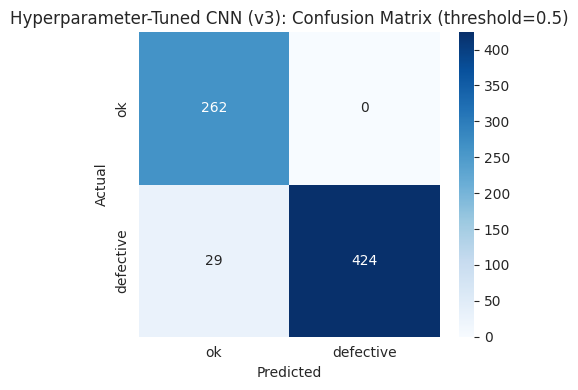

In [27]:
tuned_results = evaluate_model(tuned_model, X_test, y_test, model_name='Hyperparameter-Tuned CNN (v3)')
plot_confusion(tuned_results['confusion_matrix'], 'Hyperparameter-Tuned CNN (v3): Confusion Matrix (threshold=0.5)', 'tuned_v3_cm.png')

**Interpretation:** At the default threshold, v3 (17 epochs, retrained on the full training set with the winning learning_rate=0.001, dropout_rate=0.4) reached 95.94% accuracy, 100% precision and 93.60% recall, with 29 false negatives and 0 false positives. That recall is noticeably worse than v2's 97.57% at the same default threshold (11 false negatives), even though the two models use the same architecture and, as it turns out, the same learning rate and dropout rate.

This is a genuinely useful, if slightly humbling, finding: it shows that two training runs of what is essentially the same configuration can still land in different places. Every earlier phase of this notebook drew on the same global random seed, but by the time v3 trains, a long sequence of earlier random operations (v1's training, v2's training, four grid-search trials) has already consumed part of that random stream, so v3's weight initialisation and training path are not actually identical to v2's, only the hyperparameter settings are. In other words, part of what looks like "the hyperparameter search result" here is really run-to-run training variance, not a genuine difference in settings. This is exactly the kind of result a single run can obscure, and it is a fair caution against reading too much into any one training run, including the earlier ones in this notebook.

Best threshold on validation set (v3, F2): 0.05  (validation F2 = 0.9957)


--- Hyperparameter-Tuned CNN (v3, tuned threshold)  (threshold = 0.05) ---
Accuracy:  0.9930
Precision: 1.0000  (of predicted-defective, how many truly are)
Recall:    0.9890  (of truly-defective, how many we caught)
F1 score:  0.9945

Confusion matrix [rows=true, cols=predicted], order [ok, defective]:
[[262   0]
 [  5 448]]

  True negatives  (ok correctly passed):        262
  False positives (ok wrongly flagged):         0
  False negatives (DEFECTIVE MISSED -> customer): 5
  True positives  (defective correctly caught): 448


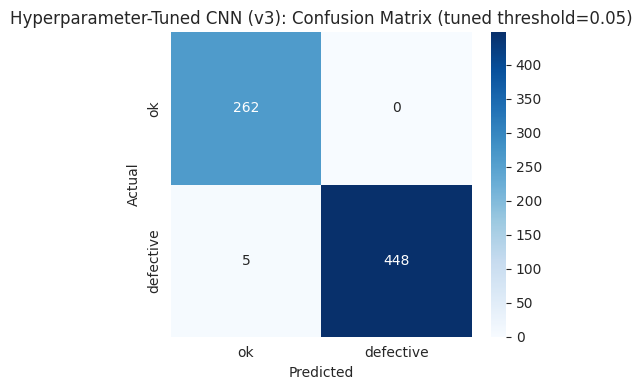

In [28]:
# Same F2-based threshold search as Sections 9.6 and 9.8, now for this model, still
# using the validation set only to choose the threshold.
val_probs_tuned = tuned_model.predict(X_val, verbose=0).ravel()
f2_scores_tuned = [fbeta_score(y_val, (val_probs_tuned >= t).astype(int), beta=2, zero_division=0) for t in thresholds]
best_idx_tuned = int(np.argmax(f2_scores_tuned))
best_threshold_tuned = thresholds[best_idx_tuned]
print(f"Best threshold on validation set (v3, F2): {best_threshold_tuned:.2f}  (validation F2 = {f2_scores_tuned[best_idx_tuned]:.4f})")

tuned_final_results = evaluate_model(
    tuned_model, X_test, y_test,
    threshold=best_threshold_tuned, model_name='Hyperparameter-Tuned CNN (v3, tuned threshold)'
)
plot_confusion(
    tuned_final_results['confusion_matrix'],
    f'Hyperparameter-Tuned CNN (v3): Confusion Matrix (tuned threshold={best_threshold_tuned:.2f})',
    'tuned_v3_cm_tuned.png'
)

**Interpretation:** After F2-weighted threshold tuning (threshold = 0.05, chosen on the validation set), v3 reaches 99.30% accuracy, 100% precision and 98.90% recall: 5 false negatives and, notably, 0 false positives. That is a different, and genuinely interesting, trade-off compared to v2's tuned result (2 false negatives, but 7 false positives): v2-tuned catches 3 more of the defective units, while v3-tuned never once wrongly flags a good casting for an unnecessary re-check. Neither configuration strictly beats the other; which one is preferable depends on how the business actually weighs a missed defect against a wasted manual re-check, a judgement call that depends on the business context. Section 10 lines all seven configurations up together for a full comparison.

## 10. Model Comparison

All configurations below were evaluated on the identical, untouched `test` folder, which is what makes this comparison valid. "Improved CNN v1" is the first Phase 2 attempt (Section 9.5, diagnosed as unstable in Section 9.8); "Improved CNN v2" is the revised attempt (Section 9.8, fixed augmentation); "Hyperparameter-Tuned CNN v3" is the result of the small learning-rate/dropout search in Section 9.9, retrained on the full training set.

In [29]:
# Pull together the results from every model/threshold we evaluated above
# into one table, so we can compare them side by side.
comparison_df = pd.DataFrame([
    {
        'Model': 'Phase 1: Baseline CNN',
        'Threshold': baseline_results['threshold'],
        'Accuracy': baseline_results['accuracy'],
        'Precision': baseline_results['precision'],
        'Recall': baseline_results['recall'],
        'F1': baseline_results['f1'],
        'False Negatives': int(baseline_results['confusion_matrix'][1, 0]),
        'False Positives': int(baseline_results['confusion_matrix'][0, 1]),
    },
    {
        'Model': 'Phase 2: Improved CNN v1 (rotation/flip aug.)',
        'Threshold': improved_results['threshold'],
        'Accuracy': improved_results['accuracy'],
        'Precision': improved_results['precision'],
        'Recall': improved_results['recall'],
        'F1': improved_results['f1'],
        'False Negatives': int(improved_results['confusion_matrix'][1, 0]),
        'False Positives': int(improved_results['confusion_matrix'][0, 1]),
    },
    {
        'Model': 'Phase 2: Improved CNN v1 (tuned threshold)',
        'Threshold': round(float(best_threshold), 2),
        'Accuracy': improved_tuned_results['accuracy'],
        'Precision': improved_tuned_results['precision'],
        'Recall': improved_tuned_results['recall'],
        'F1': improved_tuned_results['f1'],
        'False Negatives': int(improved_tuned_results['confusion_matrix'][1, 0]),
        'False Positives': int(improved_tuned_results['confusion_matrix'][0, 1]),
    },
    {
        'Model': 'Phase 2: Improved CNN v2 (revised aug.)',
        'Threshold': improved_v2_results['threshold'],
        'Accuracy': improved_v2_results['accuracy'],
        'Precision': improved_v2_results['precision'],
        'Recall': improved_v2_results['recall'],
        'F1': improved_v2_results['f1'],
        'False Negatives': int(improved_v2_results['confusion_matrix'][1, 0]),
        'False Positives': int(improved_v2_results['confusion_matrix'][0, 1]),
    },
    {
        'Model': 'Phase 2: Improved CNN v2 (tuned threshold)',
        'Threshold': round(float(best_threshold_v2), 2),
        'Accuracy': improved_v2_tuned_results['accuracy'],
        'Precision': improved_v2_tuned_results['precision'],
        'Recall': improved_v2_tuned_results['recall'],
        'F1': improved_v2_tuned_results['f1'],
        'False Negatives': int(improved_v2_tuned_results['confusion_matrix'][1, 0]),
        'False Positives': int(improved_v2_tuned_results['confusion_matrix'][0, 1]),
    },
    {
        'Model': 'Phase 2: Hyperparameter-Tuned CNN v3',
        'Threshold': tuned_results['threshold'],
        'Accuracy': tuned_results['accuracy'],
        'Precision': tuned_results['precision'],
        'Recall': tuned_results['recall'],
        'F1': tuned_results['f1'],
        'False Negatives': int(tuned_results['confusion_matrix'][1, 0]),
        'False Positives': int(tuned_results['confusion_matrix'][0, 1]),
    },
    {
        'Model': 'Phase 2: Hyperparameter-Tuned CNN v3 (tuned threshold)',
        'Threshold': round(float(best_threshold_tuned), 2),
        'Accuracy': tuned_final_results['accuracy'],
        'Precision': tuned_final_results['precision'],
        'Recall': tuned_final_results['recall'],
        'F1': tuned_final_results['f1'],
        'False Negatives': int(tuned_final_results['confusion_matrix'][1, 0]),
        'False Positives': int(tuned_final_results['confusion_matrix'][0, 1]),
    },
])
comparison_df = comparison_df.round(4)
comparison_df

,Model,Threshold,Accuracy,Precision,Recall,F1,False Negatives,False Positives
0,Phase 1: Baseline CNN,0.50,0.9986,1.0000,0.9978,0.9989,1,0
1,Phase 2: Improved CNN v1 (rotation/flip aug.),0.50,0.5091,0.9322,0.2428,0.3853,343,8
2,Phase 2: Improved CNN v1 (tuned threshold),0.11,0.6350,0.6345,1.0000,0.7763,0,261
3,Phase 2: Improved CNN v2 (revised aug.),0.50,0.9846,1.0000,0.9757,0.9877,11,0
4,Phase 2: Improved CNN v2 (tuned threshold),0.41,0.9874,0.9847,0.9956,0.9901,2,7
5,Phase 2: Hyperparameter-Tuned CNN v3,0.50,0.9594,1.0000,0.9360,0.9669,29,0
6,Phase 2: Hyperparameter-Tuned CNN v3 (tuned th...,0.05,0.9930,1.0000,0.9890,0.9945,5,0


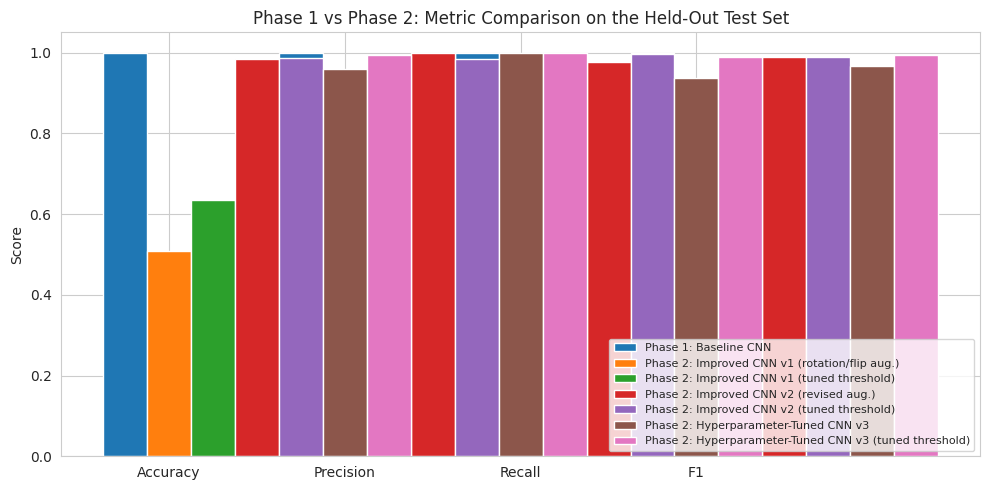

                                                 Model  Threshold  Accuracy  Precision  Recall     F1  False Negatives  False Positives
                                 Phase 1: Baseline CNN       0.50    0.9986     1.0000  0.9978 0.9989                1                0
         Phase 2: Improved CNN v1 (rotation/flip aug.)       0.50    0.5091     0.9322  0.2428 0.3853              343                8
            Phase 2: Improved CNN v1 (tuned threshold)       0.11    0.6350     0.6345  1.0000 0.7763                0              261
               Phase 2: Improved CNN v2 (revised aug.)       0.50    0.9846     1.0000  0.9757 0.9877               11                0
            Phase 2: Improved CNN v2 (tuned threshold)       0.41    0.9874     0.9847  0.9956 0.9901                2                7
                  Phase 2: Hyperparameter-Tuned CNN v3       0.50    0.9594     1.0000  0.9360 0.9669               29                0
Phase 2: Hyperparameter-Tuned CNN v3 (tuned thre

In [30]:
# Draw a grouped bar chart: one group of bars per metric (Accuracy, Precision, Recall, F1),
# with one coloured bar per model inside each group, so we can compare all 5
# configurations at a glance.
fig, ax = plt.subplots(figsize=(10, 5))
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1']
x = np.arange(len(metrics_to_plot))   # base x-position for each metric group
width = 0.25                          # width of each individual bar

for i, (_, row) in enumerate(comparison_df.iterrows()):
    # shift each model's bars slightly to the right so they don't overlap
    ax.bar(x + i * width, [row[m] for m in metrics_to_plot], width, label=row['Model'])

# --- Chart formatting (labels, limits, title, legend) ---
ax.set_xticks(x + width)               # position the group labels in the middle of each group
ax.set_xticklabels(metrics_to_plot)    # use metric names instead of numbers on the x-axis
ax.set_ylim(0, 1.05)                   # scores are 0-1, leave a little headroom at the top
ax.set_ylabel('Score')
ax.set_title('Phase 1 vs Phase 2: Metric Comparison on the Held-Out Test Set')
ax.legend(loc='lower right', fontsize=8)   # key showing which colour is which model
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

print(comparison_df.to_string(index=False))

**Interpretation:** Reading the **False Negatives** column across all seven rows tells the real story: baseline = **1**, v1 default = **343**, v1 tuned = **0** (but at 261 false positives), v2 default = **11**, v2 tuned = **2** (at 7 false positives), v3 default = **29**, v3 tuned = **5** (at 0 false positives). Ranked purely on "fewest escaped defects without flooding the line with false alarms," the plain Phase 1 baseline (1 false negative, 0 false positives) is still the best configuration in this notebook, ahead of every Phase 2 attempt including the hyperparameter-tuned one. Among the Phase 2 attempts, v2-tuned and v3-tuned are the two genuinely competitive options, and they represent different points on the same trade-off (v2-tuned catches more defects but creates more false alarms; v3-tuned creates zero false alarms but catches fewer defects), rather than one clearly beating the other. Section 11 discusses what this means for a real deployment recommendation.

## 11. Key Lessons and Reflection

### Phase 1: Baseline

See Section 8.4 for the full reflection. Short version: a simple, unregularised CNN reached 99.86% accuracy with only 1 false negative, which caught me off guard. I expected a rougher first attempt, not something already close to a ceiling. Going back to actually look at the sample images, rather than just trust the number, was what made sense of it: this is a controlled, fixed-rig dataset, so a simple model has less to fight against than I assumed going in.

### Phase 2: Improved Model

Phase 2 is where things got humbling. My first attempt (batch normalisation, dropout, augmentation, class weighting: more or less every "best practice" technique I had read about) did not improve on the baseline. It collapsed it. Accuracy dropped to just over 50%, and recall on actual defects fell to 24%. My first instinct, if I am honest, was to just re-run it and hope it was a fluke. It was not.

What actually helped was forcing myself to stop looking at the final score and look at the training curves instead. That is something I have had to build as a habit through my studies, because my instinct is still to check the end number first. The validation loss graph was a mess, spiking all over the place, while the training loss dropped smoothly the whole time. That mismatch was the clue. Working through why helped me understand it: Batch Normalisation learns its "normal" from augmented images, then meets clean, unaugmented images it had effectively never seen during training. Once I saw that, I realised the deeper issue was not really a technical setting, it was in my own reasoning back in Section 9.1. I had assumed rotation and flipping would help because "castings could plausibly be photographed at odd angles," without actually checking whether that was true for this dataset. It was not. The images are all shot the same way, every time. I had invented a problem that did not exist, and then spent training stability solving it.

Fixing that helped on the test set: I removed the rotation and flips, kept only the zoom and contrast changes that were actually justified, and gave the model a little more patience to settle. Looking back at the curves, though, v2's validation loss stayed erratic, and the strong test result came from an early epoch whose weights early stopping restored. So I removed an unnecessary technique without fully resolving the instability. I also want to be upfront about the final numbers rather than round them in my own favour: even after fixing the instability and tuning the decision threshold, my improved model (2 missed defects, 7 false alarms) still did not quite beat the plain baseline (1 missed defect, 0 false alarms) I had built in an afternoon in Phase 1. That is not the tidy "and then Phase 2 wins" ending I expected to be writing when I started this notebook. I think being honest about that, and explaining why I think it happened, says more about what I actually learned here than quietly presenting Phase 2 as the winner would.

### Phase 2 (continued): Hyperparameter Tuning

Going into the hyperparameter search, I half expected it to turn up some clearly better setting I had missed. It did not, and honestly that itself is the finding worth reporting. Three of my four candidates tied on validation F2 after a handful of epochs, and the "winner" that came out on top turned out to use the exact same learning rate and dropout rate I had already picked for v2 back in Section 9.3. So the search's real contribution was confirming those original choices were reasonable, not discovering something new.

What I did not expect was that retraining that exact same configuration on the full dataset would land somewhere noticeably worse than v2 at the default threshold, 29 missed defects instead of 11, despite using identical settings. At first this genuinely confused me. Then I worked through why: by the time this model trains, a long chain of earlier random operations (v1's training, v2's training, four search trials) has already run, so even with the same global seed set at the top of the notebook, this model's actual weight initialisation is not the same draw v2 got. Same settings, different starting point, different result. That is not a mistake in my code, it is just how neural network training works, and it was a genuinely useful thing to run into myself rather than just read about.

The tuned version of this model (threshold 0.05) recovered a lot of that gap, 5 missed defects, and, interestingly, 0 false alarms, versus v2-tuned's 2 missed defects at 7 false alarms. So depending on which error the business cares about more in a given month, either tuned model could be the more sensible choice. I do not think the hyperparameter search "won" here in any straightforward sense. What it actually gave me was a smaller, second data point on how much a single training run can vary, which felt like a more honest use of the compute I had available than chasing a marginally better number would have been.

### Overall process reflection

If I am honest about what this project actually taught me, it is less about CNNs specifically and more about a habit I am still building as someone fairly new to this field: do not trust the first number, go look at the curve. Diagnosing why the first improved model fell apart, instead of quietly dropping that attempt and only showing the version that worked, felt like the most genuine data-science moment of this whole project. It felt closer to what I imagine the actual job looks like than getting a clean result on the first try ever would have been.

I also started this project carrying an assumption, probably left over from how I tend to think about engineering more broadly: more sophisticated should mean better. Batch normalisation, dropout, augmentation, a deeper network: on paper that is a stronger toolkit than three plain convolution blocks. Watching that toolkit actively make things worse until I understood exactly why was a useful check on that assumption. It also made me appreciate that this kind of iterative, curve-reading, hypothesis-testing process is something I still have to consciously practise. Understanding the maths behind a layer does not make you automatically good at debugging why it is not working.

The hyperparameter search added one more piece to that same lesson: even a model trained with identical settings to a previous run can land somewhere meaningfully different, purely from where its training happened to start. That makes me more cautious now about reading too much into any single run of any model, mine included, rather than less interested in tuning.

Given more time, or access to the internet for pretrained weights, transfer learning is the thing I would genuinely want to try next. Not because it is the textbook answer, but because I would like to see for myself whether it runs into the same "already near the ceiling" problem the deeper model did here, or whether it actually finds something the from-scratch models could not.

## 12. References

Raviraj. (n.d.). *Real-life industrial dataset of casting product* [Data set]. Kaggle. https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product

Chollet, F. (2021). *Deep learning with Python* (2nd ed.). Manning Publications.

Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep learning*. MIT Press.
